## Assignment: Image recognition
- Alumno 1:
- Alumno 2:
- Alumno 3:

The goals of the assignment are:
* Develop proficiency in using Tensorflow/Keras for training Neural Nets (NNs).
* Put into practice the acquired knowledge to optimize the parameters and architecture of a feedforward Neural Net (ffNN), in the context of an image recognition problem.
* Put into practice NNs specially conceived for analysing images. Design and optimize the parameters of a Convolutional Neural Net (CNN) to deal with previous task.
* Train popular architectures from scratch (e.g., GoogLeNet, VGG, ResNet, ...), and compare the results with the ones provided by their pre-trained versions using transfer learning.

Follow the link below to download the classification data set  “xview_recognition”: [https://drive.upm.es/s/2DDPE2zHw5dbM3G](https://drive.upm.es/s/2DDPE2zHw5dbM3G)

In [1]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

2026-10-17 19:37:00.096304: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-17 19:37:00.125305: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-17 19:37:00.125326: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-17 19:37:00.126288: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-17 19:37:00.131953: I tensorflow/core/platform/cpu_feature_guar

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


2026-10-17 19:37:00.995154: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-17 19:37:01.305504: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-17 19:37:01.305565: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


In [2]:
import uuid
import numpy as np

class GenericObject:
    """
    Generic object data.
    """
    def __init__(self):
        self.id = uuid.uuid4()
        self.bb = (-1, -1, -1, -1)
        self.category= -1
        self.score = -1

class GenericImage:
    """
    Generic image data.
    """
    def __init__(self, filename):
        self.filename = filename
        self.tile = np.array([-1, -1, -1, -1])  # (pt_x, pt_y, pt_x+width, pt_y+height)
        self.objects = list([])

    def add_object(self, obj: GenericObject):
        self.objects.append(obj)

In [3]:
categories = {0: 'Cargo plane', 1: 'Small car', 2: 'Bus', 3: 'Truck', 4: 'Motorboat', 5: 'Fishing vessel', 6: 'Dump truck', 7: 'Excavator', 8: 'Building', 9: 'Helipad', 10: 'Storage tank', 11: 'Shipping container', 12: 'Pylon'}

In [4]:
# CAMBIO DE RUTAS: localizar PROJECT desde el directorio de trabajo o sus padres.
# Permite ejecutar desde la raíz del repositorio, PROJECT o la carpeta del notebook.
from pathlib import Path

PROJECT_DIR = None
for parent in (Path.cwd(), *Path.cwd().parents):
    for candidate in (parent, parent / 'PROJECT'):
        if (candidate / 'xview_recognition' / 'xview_ann_train.json').is_file():
            PROJECT_DIR = candidate.resolve()
            break
    if PROJECT_DIR is not None:
        break
if PROJECT_DIR is None:
    raise FileNotFoundError('No se encuentra PROJECT/xview_recognition desde el directorio de trabajo.')

DATA_DIR = PROJECT_DIR / 'xview_recognition'
# EXPERIMENTO 07: resultados propios para no sobrescribir otras ejecuciones.
# BASELINE_DIR = PROJECT_DIR / 'experiments' / 'reg_challenge'
# MODEL_PATH = BASELINE_DIR / 'model.keras'
# PREDICTION_PATH = BASELINE_DIR / 'prediction.json'
EXPERIMENT_DIR = PROJECT_DIR / 'experiments' / 'reg_challenge' / 'experiment_07'
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = EXPERIMENT_DIR / 'model.keras'
PREDICTION_PATH = EXPERIMENT_DIR / 'prediction.json'
print('Dataset:', DATA_DIR)
print('Resultados:', EXPERIMENT_DIR)

# CAMBIO respecto a ffNN_example.ipynb: Reducir RGB a 32 × 32 con promedio, normalizar a [0, 1] y cerrar cada archivo tras su lectura.
# Líneas sustituidas del original (fragmentos en su orden original):
#     warnings.filterwarnings('ignore', category=rasterio.errors.NotGeoreferencedWarning)
#     src_raster = rasterio.open('../PROJECT/xview_recognition/'+filename, 'r')
#     input_type = src_raster.profile['dtype']
#     input_channels = src_raster.count
#     img = np.zeros((src_raster.height, src_raster.width, src_raster.count), dtype=input_type)
#     for band in range(input_channels):
#         img[:, :, band] = src_raster.read(band+1)
#     return img

import warnings
import rasterio
from rasterio.enums import Resampling
import numpy as np

IMAGE_SIZE = (32, 32)  # (alto, ancho); tamaño original: 224 × 224.
IMAGE_CHANNELS = 3

def load_geoimage(filename):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', rasterio.errors.NotGeoreferencedWarning)
        # CAMBIO DE RUTAS: usar la raíz del dataset localizada al inicio.
        # with rasterio.open('../PROJECT/xview_recognition/' + filename, 'r') as src_raster:
        with rasterio.open(DATA_DIR / filename, 'r') as src_raster:
            if src_raster.count != IMAGE_CHANNELS or any(dtype != 'uint8' for dtype in src_raster.dtypes):
                raise ValueError(f'Se esperaba una imagen RGB uint8: {filename}')
            bands = src_raster.read(
                out_shape=(IMAGE_CHANNELS, *IMAGE_SIZE),
                resampling=Resampling.average,
                out_dtype='float32',
            )
    return np.moveaxis(bands, 0, -1) / np.float32(255.0)


Dataset: /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/xview_recognition
Resultados: /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/experiments/reg_challenge/experiment_07


#### Training
Design and train a ffNN to deal with the “xview_recognition” classification task.

In [5]:
import json

# Load database
# CAMBIO DE RUTAS: anotaciones bajo DATA_DIR.
# json_file = '../PROJECT/xview_recognition/xview_ann_train.json'
json_file = DATA_DIR / 'xview_ann_train.json'
with open(json_file) as ifs:
    json_data = json.load(ifs)
ifs.close()

In [6]:
import numpy as np

counts = dict.fromkeys(categories.values(), 0)
anns = []
for json_img, json_ann in zip(json_data['images'].values(), json_data['annotations'].values()):
    image = GenericImage(json_img['filename'])
    image.tile = np.array([0, 0, json_img['width'], json_img['height']])
    obj = GenericObject()
    obj.bb = (int(json_ann['bbox'][0]), int(json_ann['bbox'][1]), int(json_ann['bbox'][2]), int(json_ann['bbox'][3]))
    obj.category = json_ann['category_id']
    # Contar los objetos de cada categoría
    counts[obj.category] += 1
    image.add_object(obj)
    anns.append(image)
print(counts)

{'Cargo plane': 635, 'Small car': 3324, 'Bus': 1768, 'Truck': 2210, 'Motorboat': 1069, 'Fishing vessel': 706, 'Dump truck': 1236, 'Excavator': 789, 'Building': 3594, 'Helipad': 111, 'Storage tank': 1469, 'Shipping container': 1523, 'Pylon': 312}


In [7]:
from sklearn.model_selection import train_test_split

anns_train, anns_valid = train_test_split(anns, test_size=0.1, random_state=1, shuffle=True)
print('Number of training images: ' + str(len(anns_train)))
print('Number of validation images: ' + str(len(anns_valid)))

Number of training images: 16871
Number of validation images: 1875


In [8]:
# CAMBIO respecto a ffNN_example.ipynb: Entrada 32 × 32 × 3 y tres capas ocultas de 256, 128 y 64 neuronas con ReLU; salida de 13 clases.
# Líneas sustituidas del original (fragmentos en su orden original):
# from tensorflow.keras.layers import Dense, Activation, Flatten
#
# model.add(Flatten(input_shape=(224, 224, 3)))
# model.add(Activation('relu'))

from tensorflow.keras.models import Sequential
# EXPERIMENTO 07: incorporar Dropout a la definición de la red.
# from tensorflow.keras.layers import Input, Dense, Activation, Flatten
from tensorflow.keras.layers import Input, Dense, Activation, Flatten, Dropout

print('Load model')
model = Sequential()
model.add(Input(shape=(*IMAGE_SIZE, IMAGE_CHANNELS)))
model.add(Flatten())
model.add(Dense(256, activation='relu'))
# EXPERIMENTO 07: reducir Dropout del 20 % al 10 % respecto al experimento 03.
# Configuración del experimento 03: model.add(Dropout(0.2))
model.add(Dropout(0.1))
model.add(Dense(128, activation='relu'))
# EXPERIMENTO 07: reducir Dropout del 20 % al 10 % respecto al experimento 03.
# Configuración del experimento 03: model.add(Dropout(0.2))
model.add(Dropout(0.1))
model.add(Dense(64, activation='relu'))
# EXPERIMENTO 07: reducir Dropout del 20 % al 10 % respecto al experimento 03.
# Configuración del experimento 03: model.add(Dropout(0.2))
model.add(Dropout(0.1))
model.add(Dense(len(categories)))
model.add(Activation('softmax'))
model.summary()


Load model
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 3072)              0         
                                                                 
 dense (Dense)               (None, 256)               786688    
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense_1 (Dense)             (None, 128)               32896     
                                                                 
 dropout_1 (Dropout)         (None, 128)               0         
                                                                 
 dense_2 (Dense)             (None, 64)                8256      
                                                                 
 dropout_2 (Dropout)         (None, 64)      

2026-10-17 19:37:01.981368: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-17 19:37:01.981442: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-17 19:37:01.981472: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-17 19:37:02.223307: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-17 19:37:02.223358: I external/local_xla/xla/stream_executor

In [9]:
# CAMBIO respecto a ffNN_example.ipynb: Sustituir Adam por SGD con LR inicial 0.001, momentum 0.9, Nesterov y clipnorm 1.0.
# Líneas sustituidas del original (fragmentos en su orden original):
# from tensorflow.keras.optimizers import Adam
# opt = Adam(learning_rate=1e-3, beta_1=0.9, beta_2=0.999, epsilon=1e-8, amsgrad=True, clipnorm=1.0)

from tensorflow.keras.optimizers import SGD

opt = SGD(learning_rate=1e-3, momentum=0.9, nesterov=True, clipnorm=1.0)
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])


In [10]:
# CAMBIO respecto a ffNN_example.ipynb: Reducir LR por factor 0.2 tras 5 épocas sin mejora y detener tras 10; monitorizar val_accuracy.
# Líneas sustituidas del original (fragmentos en su orden original):
# reduce_lr = ReduceLROnPlateau('val_accuracy', factor=0.1, patience=10, verbose=1)
# early_stop = EarlyStopping('val_accuracy', patience=40, verbose=1)

from tensorflow.keras.callbacks import TerminateOnNaN, EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# CAMBIO DE RUTAS: guardar en la carpeta del experimento 07.
# model_checkpoint = ModelCheckpoint('model.keras', monitor='val_accuracy', verbose=1, save_best_only=True)
model_checkpoint = ModelCheckpoint(str(MODEL_PATH), monitor='val_accuracy', verbose=1, save_best_only=True)
reduce_lr = ReduceLROnPlateau('val_accuracy', factor=0.2, patience=5, verbose=1)
early_stop = EarlyStopping('val_accuracy', patience=10, verbose=1)
terminate = TerminateOnNaN()
callbacks = [model_checkpoint, reduce_lr, early_stop, terminate]


In [11]:
# CAMBIO respecto a ffNN_example.ipynb: Sustituir el generador por una función de carga única de imágenes y etiquetas en memoria.
# Líneas sustituidas del original (fragmentos en su orden original):
# def generator_images(objs, batch_size, do_shuffle=False):
#     while True:
#         if do_shuffle:
#             np.random.shuffle(objs)
#         groups = [objs[i:i+batch_size] for i in range(0, len(objs), batch_size)]
#         for group in groups:
#             images, labels = [], []
#             for (filename, obj) in group:
#                 images.append(load_geoimage(filename))
#                 probabilities = np.zeros(len(categories))
#                 probabilities[list(categories.values()).index(obj.category)] = 1
#                 labels.append(probabilities)
#             images = np.array(images).astype(np.float32)
#             labels = np.array(labels).astype(np.float32)
#             yield images, labels

category_names = list(categories.values())
category_to_index = {name: index for index, name in enumerate(category_names)}

def prepare_images(objs):
    images = np.empty((len(objs), *IMAGE_SIZE, IMAGE_CHANNELS), dtype=np.float32)
    labels = np.zeros((len(objs), len(categories)), dtype=np.float32)
    for index, (filename, obj) in enumerate(objs):
        images[index] = load_geoimage(filename)
        labels[index, category_to_index[obj.category]] = 1.0
    return images, labels


In [12]:
# CAMBIO respecto a ffNN_example.ipynb: Usar batch 8 y precargar entrenamiento y validación una sola vez.
# Líneas sustituidas del original (fragmentos en su orden original):
# batch_size = 16
# train_generator = generator_images(objs_train, batch_size, do_shuffle=True)
# valid_generator = generator_images(objs_valid, batch_size, do_shuffle=False)

objs_train = [(ann.filename, obj) for ann in anns_train for obj in ann.objects]
objs_valid = [(ann.filename, obj) for ann in anns_valid for obj in ann.objects]
batch_size = 8

x_train, y_train = prepare_images(objs_train)
x_valid, y_valid = prepare_images(objs_valid)
print(f'Entrenamiento: {x_train.shape}, rango [{x_train.min():.3f}, {x_train.max():.3f}]')
print(f'Validación: {x_valid.shape}, rango [{x_valid.min():.3f}, {x_valid.max():.3f}]')
print(f'Imágenes en memoria: {(x_train.nbytes + x_valid.nbytes) / 1024**2:.1f} MiB')


Entrenamiento: (16871, 32, 32, 3), rango [0.000, 1.000]
Validación: (1875, 32, 32, 3), rango [0.000, 1.000]
Imágenes en memoria: 219.7 MiB


In [13]:
# CAMBIO respecto a ffNN_example.ipynb: Entrenar con arrays precargados y un máximo de 100 épocas, sin pasos manuales del generador.
# Líneas sustituidas del original (fragmentos en su orden original):
# import math
#
# epochs = 20
# train_steps = math.ceil(len(objs_train)/batch_size)
# valid_steps = math.ceil(len(objs_valid)/batch_size)
# h = model.fit(train_generator, steps_per_epoch=train_steps, validation_data=valid_generator, validation_steps=valid_steps, epochs=epochs, callbacks=callbacks, verbose=1)
#
# print('Best validation model: epoch ' + str(best_idx+1), ' - val_accuracy ' + str(best_value))

import numpy as np

print('Training model')
epochs = 100
h = model.fit(
    x_train, y_train,
    batch_size=batch_size,
    validation_data=(x_valid, y_valid),
    shuffle=True,
    epochs=epochs,
    callbacks=callbacks,
    verbose=1,
)
best_idx = int(np.argmax(h.history['val_accuracy']))
best_value = np.max(h.history['val_accuracy'])
print('Best validation model: epoch ' + str(best_idx + 1) + ' - val_accuracy ' + str(best_value))


Training model
Epoch 1/100


2026-10-17 19:37:46.103572: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2026-10-17 19:37:46.928222: I external/local_xla/xla/service/service.cc:168] XLA service 0x79327dabc020 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-17 19:37:46.928262: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA GeForce RTX 4070 Ti, Compute Capability 8.9
2026-10-17 19:37:46.963178: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
I0000 00:00:1792258667.017673   73961 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2109/2109 [==============================] - ETA: 0s - loss: 2.1715 - accuracy: 0.2619
Epoch 1: val_accuracy improved from -inf to 0.36213, saving model to /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/experiments/reg_challenge/experiment_07/model.keras
2109/2109 [==============================] - 14s 6ms/step - loss: 2.1715 - accuracy: 0.2619 - val_loss: 1.9119 - val_accuracy: 0.3621 - lr: 0.0010
Epoch 2/100
2100/2109 [============================>.] - ETA: 0s - loss: 1.8509 - accuracy: 0.3644
Epoch 2: val_accuracy improved from 0.36213 to 0.41707, saving model to /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/experiments/reg_challenge/experiment_07/model.keras
2109/2109 [==============================] - 12s 6ms/step - loss: 1.8502 - accuracy: 0.3644 - val_loss: 1.7383 - val_accuracy: 0.4171 - lr: 0.0010
Epoch 3/100
2102/2109 [============================>.] - ETA: 0s - loss: 1.7351 - accuracy: 0.4003
Epoch 3: val_accuracy improved from 0.41707 to 0.4

#### Validation
Compute validation metrics.

In [14]:
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

def draw_confusion_matrix(cm, categories):
    # Draw confusion matrix
    fig = plt.figure(figsize=[6.4*pow(len(categories), 0.5), 4.8*pow(len(categories), 0.5)])
    ax = fig.add_subplot(111)
    cm = cm.astype('float') / np.maximum(cm.sum(axis=1)[:, np.newaxis], np.finfo(np.float64).eps)
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.colormaps['Blues'])
    ax.figure.colorbar(im, ax=ax)
    ax.set(xticks=np.arange(cm.shape[1]), yticks=np.arange(cm.shape[0]), xticklabels=list(categories.values()), yticklabels=list(categories.values()), ylabel='Annotation', xlabel='Prediction')
    # Rotate the tick labels and set their alignment
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    # Loop over data dimensions and create text annotations
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], '.2f'), ha="center", va="center", color="white" if cm[i, j] > thresh else "black", fontsize=int(20-pow(len(categories), 0.5)))
    fig.tight_layout()
    plt.show()

In [15]:
# CAMBIO respecto a ffNN_example.ipynb: Reutilizar las imágenes de validación precargadas y predecir por lotes con el mejor checkpoint.
# Líneas sustituidas del original (fragmentos en su orden original):
# y_true, y_pred = [], []
# for ann in anns_valid:
#     image = load_geoimage(ann.filename)
#     for obj_pred in ann.objects:
#         warped_image = np.expand_dims(image, 0)
#         predictions = model.predict(warped_image, verbose=0)
#         pred_category = list(categories.values())[np.argmax(predictions)]
#         pred_score = np.max(predictions)
#         y_true.append(obj_pred.category)
#         y_pred.append(pred_category)

import numpy as np

# CAMBIO DE RUTAS: cargar el mismo checkpoint que guarda el callback.
# model.load_weights('model.keras')
model.load_weights(str(MODEL_PATH))
valid_predictions = model.predict(x_valid, batch_size=batch_size, verbose=0)
y_true = [category_names[index] for index in np.argmax(y_valid, axis=1)]
y_pred = [category_names[index] for index in np.argmax(valid_predictions, axis=1)]


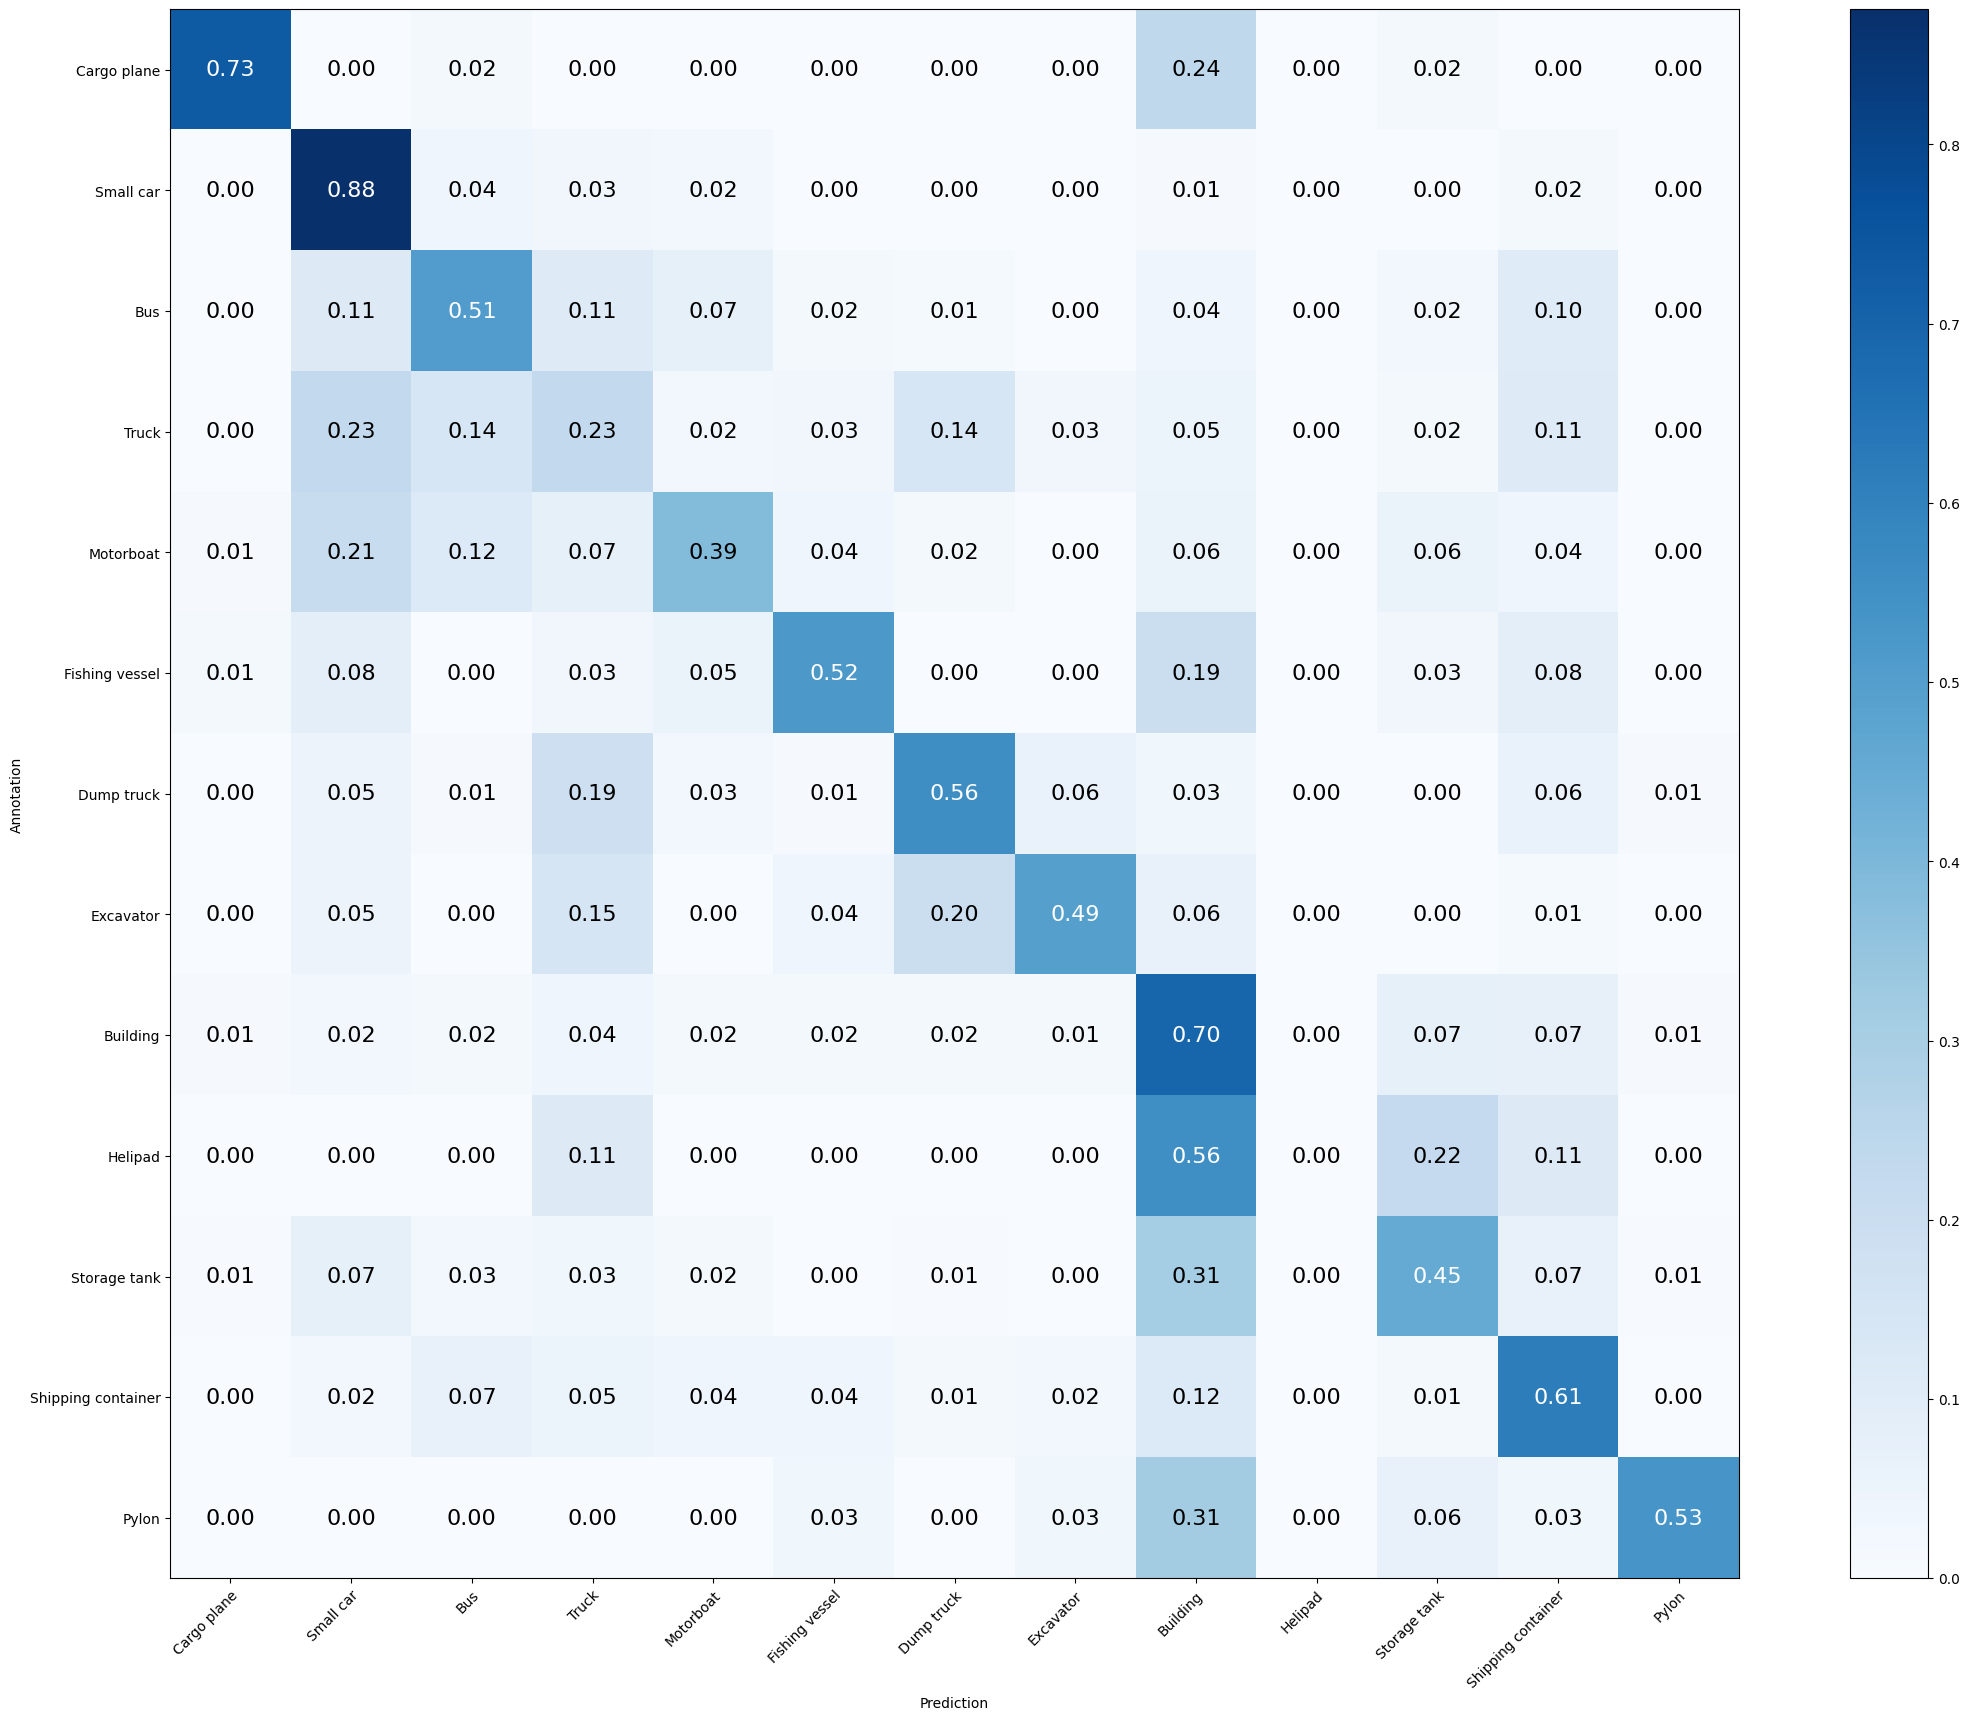

In [16]:
from sklearn.metrics import confusion_matrix

# Compute the confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(categories.values()))
draw_confusion_matrix(cm, categories)

In [17]:
import numpy as np

# Compute the accuracy
correct_samples_class = np.diag(cm).astype(float)
total_samples_class = np.sum(cm, axis=1).astype(float)
total_predicts_class = np.sum(cm, axis=0).astype(float)
print('Mean Accuracy: %.3f%%' % (np.sum(correct_samples_class) / np.sum(total_samples_class) * 100))
acc = correct_samples_class / np.maximum(total_samples_class, np.finfo(np.float64).eps)
print('Mean Recall: %.3f%%' % (acc.mean() * 100))
acc = correct_samples_class / np.maximum(total_predicts_class, np.finfo(np.float64).eps)
print('Mean Precision: %.3f%%' % (acc.mean() * 100))
for idx in range(len(categories)):
    # True/False Positives (TP/FP) refer to the number of predicted positives that were correct/incorrect.
    # True/False Negatives (TN/FN) refer to the number of predicted negatives that were correct/incorrect.
    tp = cm[idx, idx]
    fp = sum(cm[:, idx]) - tp
    fn = sum(cm[idx, :]) - tp
    tn = sum(np.delete(sum(cm) - cm[idx, :], idx))
    # True Positive Rate: proportion of real positive cases that were correctly predicted as positive.
    recall = tp / np.maximum(tp+fn, np.finfo(np.float64).eps)
    # Precision: proportion of predicted positive cases that were truly real positives.
    precision = tp / np.maximum(tp+fp, np.finfo(np.float64).eps)
    # True Negative Rate: proportion of real negative cases that were correctly predicted as negative.
    specificity = tn / np.maximum(tn+fp, np.finfo(np.float64).eps)
    # Dice coefficient refers to two times the intersection of two sets divided by the sum of their areas.
    # Dice = 2 |A∩B| / (|A|+|B|) = 2 TP / (2 TP + FP + FN)
    f1_score = 2 * ((precision * recall) / np.maximum(precision+recall, np.finfo(np.float64).eps))
    print('> %s: Recall: %.3f%% Precision: %.3f%% Specificity: %.3f%% Dice: %.3f%%' % (list(categories.values())[idx], recall*100, precision*100, specificity*100, f1_score*100))

Mean Accuracy: 57.707%
Mean Recall: 50.724%
Mean Precision: 54.001%
> Cargo plane: Recall: 72.881% Precision: 87.755% Specificity: 99.670% Dice: 79.630%
> Small car: Recall: 87.538% Precision: 67.925% Specificity: 91.203% Dice: 76.494%
> Bus: Recall: 50.575% Precision: 52.381% Specificity: 95.297% Dice: 51.462%
> Truck: Recall: 22.822% Precision: 35.714% Specificity: 93.941% Dice: 27.848%
> Motorboat: Recall: 38.532% Precision: 46.667% Specificity: 97.282% Dice: 42.211%
> Fishing vessel: Recall: 52.055% Precision: 55.882% Specificity: 98.335% Dice: 53.901%
> Dump truck: Recall: 55.932% Precision: 50.769% Specificity: 96.357% Dice: 53.226%
> Excavator: Recall: 49.383% Precision: 62.500% Specificity: 98.662% Dice: 55.172%
> Building: Recall: 69.697% Precision: 63.728% Specificity: 90.476% Dice: 66.579%
> Helipad: Recall: 0.000% Precision: 0.000% Specificity: 100.000% Dice: 0.000%
> Storage tank: Recall: 45.395% Precision: 57.500% Specificity: 97.040% Dice: 50.735%
> Shipping container: R

#### Testing
Try to improve the results provided in the competition.

In [18]:
import os
import numpy as np

anns = []
# CAMBIO DE RUTAS: recorrer el test desde DATA_DIR.
# for (dirpath, dirnames, filenames) in os.walk('../PROJECT/xview_recognition/xview_test'):
for (dirpath, dirnames, filenames) in os.walk(DATA_DIR / 'xview_test'):
    for filename in filenames:
        # CAMBIO DE RUTAS: ruta relativa al dataset, sin recortar caracteres.
        # image = GenericImage(dirpath[29:] + '/' + filename)
        relative_path = (Path(dirpath) / filename).relative_to(DATA_DIR)
        image = GenericImage(relative_path.as_posix())
        image.tile = np.array([0, 0, 224, 224])
        obj = GenericObject()
        obj.bb = (0, 0, 224, 224)
        obj.category = dirpath[dirpath.rfind('/')+1:]
        image.add_object(obj)
        anns.append(image)
print('Number of testing images: ' + str(len(anns)))

Number of testing images: 2365


In [19]:
# CAMBIO respecto a ffNN_example.ipynb: Precargar el test normalizado a 32 × 32 y predecir por lotes; conservar metadatos originales.
# Líneas sustituidas del original (fragmentos en su orden original):
#     image = load_geoimage(ann.filename)
#
#         warped_image = np.expand_dims(image, 0)
#         predictions = model.predict(warped_image, verbose=0)
#         pred_category = list(categories.values())[np.argmax(predictions)]

import numpy as np

# CAMBIO DE RUTAS: cargar el checkpoint del baseline para el test.
# model.load_weights('model.keras')
model.load_weights(str(MODEL_PATH))
predictions_data = {"images": {}, "annotations": {}}
x_test = np.empty((len(anns), *IMAGE_SIZE, IMAGE_CHANNELS), dtype=np.float32)
for idx, ann in enumerate(anns):
    x_test[idx] = load_geoimage(ann.filename)
test_predictions = model.predict(x_test, batch_size=batch_size, verbose=0)

for idx, ann in enumerate(anns):
    image_data = {"image_id": ann.filename.split('/')[-1], "filename": ann.filename, "width": int(ann.tile[2]), "height": int(ann.tile[3])}
    predictions_data["images"][idx] = image_data
    for obj_pred in ann.objects:
        predictions = test_predictions[idx]
        pred_category = category_names[np.argmax(predictions)]
        pred_score = np.max(predictions)
        annotation_data = {"image_id": ann.filename.split('/')[-1], "category_id": pred_category, "bbox": [int(x) for x in obj_pred.bb]}
        predictions_data["annotations"][idx] = annotation_data


In [20]:
# CAMBIO DE RUTAS: escribir el JSON junto al baseline.
# with open("prediction.json", "w") as outfile:
with open(PREDICTION_PATH, "w") as outfile:
    json.dump(predictions_data, outfile)